# IND320 Project part 2

Niclas

GitHub repository: https://github.com/karlsenniclas-ops/IND320-project

Streamlit app: https://ind320-project-niclas.streamlit.app

The work for this part is on the `part2` branch and is merged into `main` after peer review and feedback.

## Log

In part 2 I swapped the CSV from part 1 for NVE's Magasinstatistikk API, pulled cross-border flows from ENTSO-E, and sent the data through Cassandra and Spark into MongoDB, where the Streamlit app reads it.

The NVE API was simple to use. None of the endpoints take parameters, so I always get the whole history from 1995 and filter afterwards. HentOmråder lists four watercourse areas, but VASS 4 has no data, so it is the same nine areas as in the CSV. The columns were also the same, so the renaming and plots from part 1 could be reused almost as they were.

ENTSO-E took more work. One request gives one direction across one border for at most a year, so I loop over the nine borders between the Norwegian price areas and the neighbouring countries, both directions, for 2024 and 2025. The answer is XML. Some borders switch from hourly to 15 minute values during the period, so I use the resolution field to turn MW into MWh.

Most of my time went to getting Cassandra and Spark to run on Windows. Cassandra runs in Docker, but the Python driver would not even import on Python 3.12 until I installed pyasyncore. Spark then crashed with "Python worker exited unexpectedly" when converting the pandas DataFrame. Turning on Arrow fixed that, but then the pandas 3 text columns gave a pyarrow error, which I solved by converting them to plain strings. I also had to point JAVA_HOME to Java 17, since Java 24 does not work with Spark 3.5. In the end Spark writes the flows to Cassandra, reads them back and sums them to GWh per day, and those daily rows go to MongoDB.

In the app I followed the feedback from part 1. The page files are now in app_pages and the notebooks in notebooks, and the repository and app are renamed from Assignment1 to project. Table and Plot share a sidebar with area type and download period, and the new Transfers page shows the pie chart and line plot from MongoDB.

## AI usage

I used Claude as help during this part, mostly for the ENTSO-E data, some of the app code and getting Cassandra and Spark to work on Windows, where it helped me debug the errors along the way. I ran everything myself and checked that the outputs and plots made sense before handing it in.

## Imports and secrets

In [1]:
%matplotlib inline
import os
import sys
import tomllib
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
import pandas as pd
import requests

In [2]:
# The MongoDB connection string and ENTSO-E token are in the same secrets file as the Streamlit app uses.
# .streamlit/secrets.toml is listed in .gitignore, so it is never pushed to GitHub
with open("../.streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)

## Reservoir data from the NVE API

Part 1 used reservoirs.csv, now the data comes directly from NVE's Magasinstatistikk API. None of the four endpoints take parameters, so HentOffentligData always returns the full history.

In [3]:
NVE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

# Areas covered by the API, grouped as country (land), price areas (elspot) and watercourse areas (vassdrag)
areas = requests.get(f"{NVE_URL}/HentOmråder", timeout=30).json()[0]
for group, area_list in areas.items():
    print(group)
    for area in area_list:
        print(f"  {area['omrType']} {area['omrnr']}: {area['beskrivelse']}")

land
  NO 0: Hele landet
elspot
  EL 1: Sørøst-Norge. Omfatter østlige del av Østlandet fra Buskerud og nordover (bortsett fra den del av Innlandet som ligger vest og nord for Vågåmo).
  EL 2: Sørvest-Norge. Omfatter mesteparten av Vestfold, Telemark, Agder, Rogaland og sørlige del av Vestland.
  EL 3: Midt-Norge. Omfatter nordre og vestlige del av Vestland, den del av Innlandet som ligger vest og nord for Vågåmo, Møre og Romsdal og Trøndelag til Tunnsjødal.
  EL 4: Nord-Norge. Omfatter resten av Trøndelag og Nord-Norge.
  EL 5: Vest-Norge. Omfatter midtre del av Vestland opp til Sognefjorden og Indre Sogn, og vestlig del av Buskerud.
vassdrag
  VASS 1: Sørøst-Norge. Østlandet, Agder og deler av Rogaland.
  VASS 2: Vest-Norge. Resten av Rogaland og Vestland.
  VASS 3: Midt-Norge. Møre og Romsdal, Trøndelag og sørlige Nordland
  VASS 4: Nord-Norge. Resten av Nordland og nordover.


In [4]:
# Download the full reservoir history, same columns as reservoirs.csv in part 1
response = requests.get(f"{NVE_URL}/HentOffentligData", timeout=60)
response.raise_for_status()

df = pd.DataFrame(response.json())
df.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [5]:
# Norwegian to English column names, same as in part 1
rename_map = {
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "iso_year",
    "iso_uke": "iso_week",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_twh",
    "fylling_TWh": "stored_energy_twh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "fill_level_prev_week",
    "endring_fyllingsgrad": "fill_level_change",
}
df = df.rename(columns=rename_map)

# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14913 entries, 0 to 14912
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   14913 non-null  datetime64[us]
 1   area_type              14913 non-null  str           
 2   area_number            14913 non-null  int64         
 3   iso_year               14913 non-null  int64         
 4   iso_week               14913 non-null  int64         
 5   fill_level             14913 non-null  float64       
 6   capacity_twh           14913 non-null  float64       
 7   stored_energy_twh      14913 non-null  float64       
 8   next_publication_date  14913 non-null  str           
 9   fill_level_prev_week   14913 non-null  float64       
 10  fill_level_change      14913 non-null  float64       
dtypes: datetime64[us](1), float64(5), int64(3), str(2)
memory usage: 1.6 MB


In [6]:
# Rows per area. VASS 4 is listed by HentOmråder, but has no data
df[["area_type", "area_number"]].value_counts().sort_index()

area_type  area_number
EL         1              1657
           2              1657
           3              1657
           4              1657
           5              1657
NO         0              1657
VASS       1              1657
           2              1657
           3              1657
Name: count, dtype: int64

In [7]:
# First and last date, and which weekday the dates fall on
print("First date:", df["date"].min())
print("Last date:", df["date"].max())
print(df["date"].dt.day_name().value_counts())

First date: 1995-01-08 00:00:00
Last date: 2026-10-04 00:00:00
date
Sunday    14913
Name: count, dtype: int64


In [8]:
# Keep only rows for all of Norway, sort by date and use date as index (rows are not sorted in the API either)
value_columns = ["fill_level", "capacity_twh", "stored_energy_twh", "fill_level_prev_week", "fill_level_change"]
norway = df[df["area_type"] == "NO"].sort_values("date").set_index("date")
norway = norway[value_columns]
norway.head()

,fill_level,capacity_twh,stored_energy_twh,fill_level_prev_week,fill_level_change
date,,,,,
1995-01-08,0.607988,87.43758,53.161003,0.752631,-0.144643
1995-01-15,0.582088,87.43758,50.896374,0.607988,-0.025900
1995-01-22,0.562121,87.43758,49.150486,0.582088,-0.019967
1995-01-29,0.534222,87.43758,46.711033,0.562121,-0.027899
1995-02-05,0.506221,87.43758,44.262720,0.534222,-0.028001


### Plots from part 1, now from the API

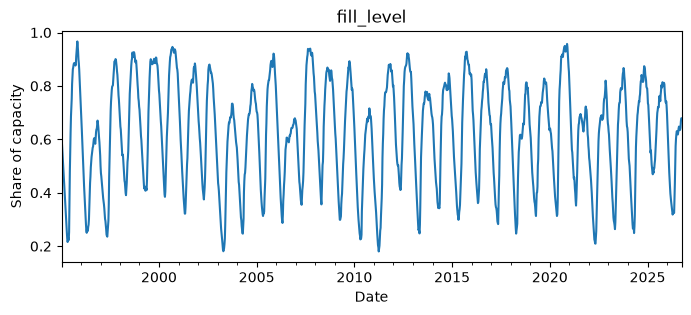

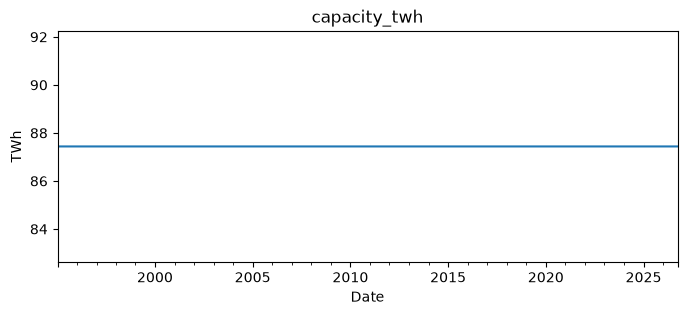

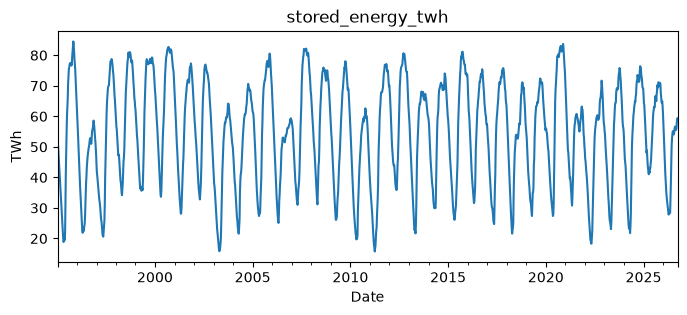

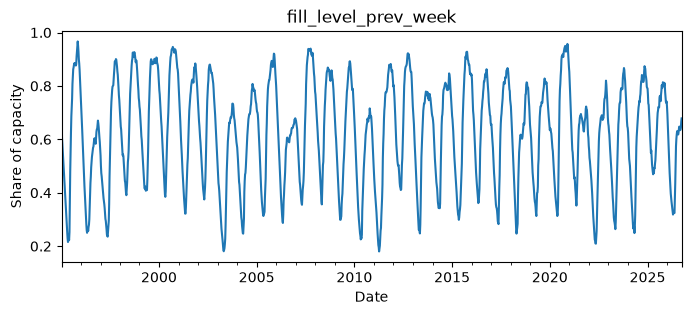

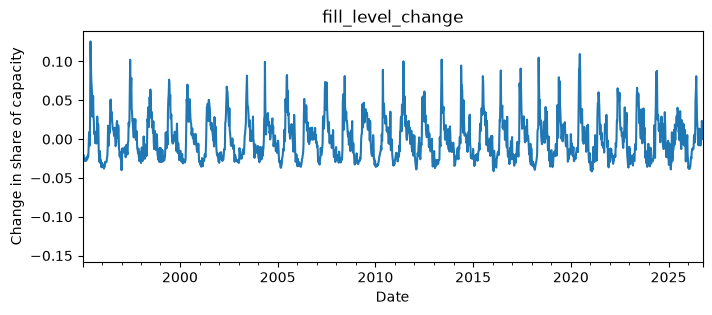

In [9]:
# Units for each column, used as y-axis labels
units = {
    "fill_level": "Share of capacity",
    "capacity_twh": "TWh",
    "stored_energy_twh": "TWh",
    "fill_level_prev_week": "Share of capacity",
    "fill_level_change": "Change in share of capacity",
}

# One plot per column, new figure each time so they don't overlap
for col in norway.columns:
    fig, ax = plt.subplots(figsize=(8, 3))
    norway[col].plot(ax=ax, title=col)
    ax.set_xlabel("Date")
    ax.set_ylabel(units[col])
    plt.show()

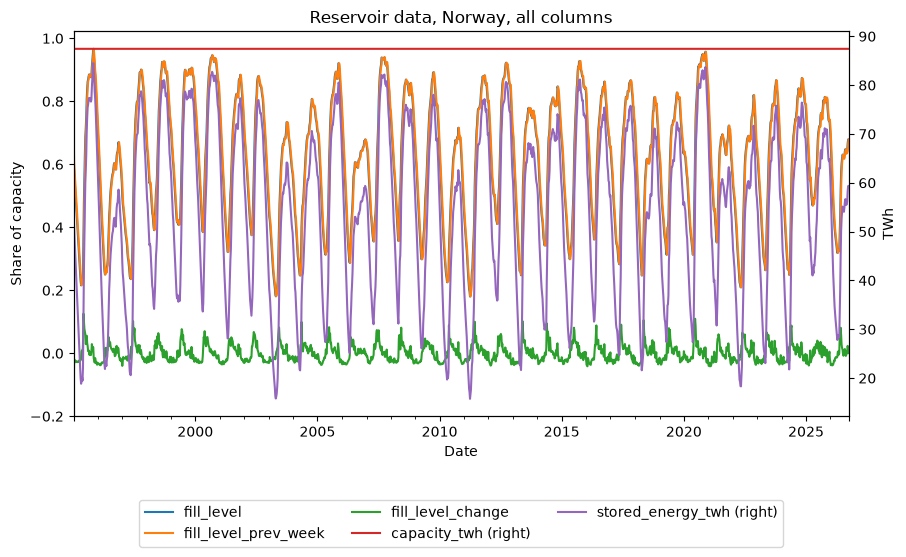

In [10]:
# Share columns first, TWh columns last: keeps the legend colours in sync with the left axis
plot_order = ["fill_level", "fill_level_prev_week", "fill_level_change", "capacity_twh", "stored_energy_twh"]
twh_columns = ["capacity_twh", "stored_energy_twh"]

fig, ax = plt.subplots(figsize=(10, 5))
norway[plot_order].plot(ax=ax, secondary_y=twh_columns)
ax.set_xlabel("Date")
ax.set_ylabel("Share of capacity")
ax.right_ax.set_ylabel("TWh")
ax.set_title("Reservoir data, Norway, all columns")

# Combine the legend from both axes and place it below the plot so it does not overlap with the graph
lines = ax.get_lines() + ax.right_ax.get_lines()
labels = [line.get_label() for line in lines]
ax.get_legend().remove()
ax.legend(lines, labels, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)

plt.show()

## Cross-border flows from ENTSO-E

Physical flows (Cross-Border Physical Flow [12.1.G], document type A11) from the ENTSO-E Transparency Platform. One request gives one direction (out_Domain to in_Domain) across one border, for at most one year. Norway's bidding zones NO1-NO5 have nine borders to other countries. I use 2024 and 2025, the last two full years. All times are UTC.

In [11]:
ENTSOE_URL = "https://web-api.tp.entsoe.eu/api"
TOKEN = secrets["entsoe"]["token"]

# EIC codes for the bidding zones on each side of the Norwegian borders
ZONES = {
    "NO1": "10YNO-1--------2",
    "NO2": "10YNO-2--------T",
    "NO3": "10YNO-3--------J",
    "NO4": "10YNO-4--------9",
    "SE1": "10Y1001A1001A44P",
    "SE2": "10Y1001A1001A45N",
    "SE3": "10Y1001A1001A46L",
    "DK1": "10YDK-1--------W",
    "FI": "10YFI-1--------U",
    "DE-LU": "10Y1001A1001A82H",
    "NL": "10YNL----------L",
    "GB": "10YGB----------A",
}

# The nine cross-border connections, Norwegian zone first
CONNECTIONS = [
    ("NO1", "SE3"),
    ("NO2", "DK1"),
    ("NO2", "NL"),
    ("NO2", "DE-LU"),
    ("NO2", "GB"),
    ("NO3", "SE2"),
    ("NO4", "SE1"),
    ("NO4", "SE2"),
    ("NO4", "FI"),
]

YEARS = [2024, 2025]

In [12]:
def get_flows(from_zone, to_zone, start, end):
    """Physical flow from one zone to another, one row per time step.

    start and end are UTC strings like "202401010000". Returns a DataFrame with
    time (UTC) and mwh, or an empty DataFrame if ENTSO-E has no data.
    """
    params = {
        "securityToken": TOKEN,
        "documentType": "A11",
        "out_Domain": ZONES[from_zone],
        "in_Domain": ZONES[to_zone],
        "periodStart": start,
        "periodEnd": end,
    }
    response = requests.get(ENTSOE_URL, params=params, timeout=60)

    # When there is no data, ENTSO-E sends an acknowledgement document with the reason instead
    if "Acknowledgement_MarketDocument" in response.text:
        reason = ET.fromstring(response.content).find(".//{*}Reason/{*}text")
        print(f"No data {from_zone} -> {to_zone}, {start[:4]}:", reason.text if reason is not None else response.status_code)
        return pd.DataFrame()
    response.raise_for_status()

    # {*} matches any XML namespace, so the code does not depend on the document version
    root = ET.fromstring(response.content)
    rows = []
    for period in root.findall(".//{*}Period"):
        period_start = pd.Timestamp(period.find("{*}timeInterval/{*}start").text)
        period_end = pd.Timestamp(period.find("{*}timeInterval/{*}end").text)

        # Resolution is PT60M or PT15M
        minutes = int(period.find("{*}resolution").text[2:-1])
        step = pd.Timedelta(minutes=minutes)

        points = {int(p.find("{*}position").text): float(p.find("{*}quantity").text) for p in period.findall("{*}Point")}

        # Some series leave out points where the value is unchanged (curve type A03), so the last value is carried forward
        mw = 0.0
        for position in range(1, int((period_end - period_start) / step) + 1):
            mw = points.get(position, mw)
            # Quantity is average MW over the step, energy is MW times hours
            rows.append({"time": period_start + (position - 1) * step, "mwh": mw * minutes / 60})

    return pd.DataFrame(rows)

In [13]:
# Two requests per connection and year: out of Norway (export) and into Norway (import)
frames = []
for no_zone, other_zone in CONNECTIONS:
    connection = f"{no_zone}-{other_zone}"
    for year in YEARS:
        start, end = f"{year}01010000", f"{year + 1}01010000"
        for direction, from_zone, to_zone in [("export", no_zone, other_zone), ("import", other_zone, no_zone)]:
            flows = get_flows(from_zone, to_zone, start, end)
            if flows.empty:
                continue
            flows["connection"] = connection
            flows["direction"] = direction
            frames.append(flows)

flows_df = pd.concat(frames, ignore_index=True)

# A border can be sent as more than one time series, keep one row per time step
flows_df = flows_df.drop_duplicates(subset=["connection", "direction", "time"])
flows_df = flows_df[["connection", "direction", "time", "mwh"]]
print(flows_df.shape)
flows_df.head()

(788976, 4)


,connection,direction,time,mwh
0,NO1-SE3,export,2024-01-01 00:00:00+00:00,0.0
1,NO1-SE3,export,2024-01-01 01:00:00+00:00,0.0
2,NO1-SE3,export,2024-01-01 02:00:00+00:00,0.0
3,NO1-SE3,export,2024-01-01 03:00:00+00:00,0.0
4,NO1-SE3,export,2024-01-01 04:00:00+00:00,0.0


In [14]:
# Number of time steps and total energy (TWh) per connection and direction
summary = flows_df.groupby(["connection", "direction"])["mwh"].agg(["count", "sum"])
summary["sum"] = summary["sum"] / 1e6
summary.rename(columns={"count": "time_steps", "sum": "twh"})

time_steps        twh
connection direction                       
NO1-SE3    export          24312   3.128863
           import          24312  11.529327
NO2-DE-LU  export          70176  14.785963
           import          70176   1.985212
NO2-DK1    export          36840  16.276462
           import          36840   2.806419
NO2-GB     export          63408  19.952732
           import          63408   0.723532
NO2-NL     export          63408   6.287884
           import          63408   1.011224
NO3-SE2    export          24312   1.566829
           import          24312   4.314524
NO4-FI     export          63408   0.533913
           import          63408   0.077642
NO4-SE1    export          24312   2.014980
           import          24312   1.947825
NO4-SE2    export          24312   0.922410
           import          24312   0.728649

## Cassandra

Cassandra runs locally in Docker, as in the book: `docker run --name my_cassandra -p 9042:9042 cassandra:latest` the first time, then `docker start my_cassandra`.

In [15]:
from cassandra.cluster import Cluster

# Connect to the local Cassandra instance
cluster = Cluster(["localhost"], port=9042)
session = cluster.connect()

# Keyspace for the project, simplest replication since it runs on one machine
session.execute("CREATE KEYSPACE IF NOT EXISTS ind320 WITH REPLICATION = {'class': 'SimpleStrategy', 'replication_factor': 1};")
session.set_keyspace("ind320")

# Connection and direction together are the partition key and time is the clustering key,
# so one line in the plots is one partition. Dropped first so a rerun starts from an empty table
session.execute("DROP TABLE IF EXISTS flows;")
session.execute("CREATE TABLE IF NOT EXISTS flows (connection text, direction text, time timestamp, mwh double, PRIMARY KEY ((connection, direction), time));")

## Spark

Insert the flows into Cassandra with Spark, then read them back and keep only what the plots and the app need.

In [16]:
# Environment variables for PySpark on my Windows machine.
# Java 17 is set directly, since Spark 3.5 does not work with the newer Java 24 that is also installed
os.environ["JAVA_HOME"] = "C:/Program Files/Amazon Corretto/jdk17.0.14_7"
os.environ["HADOOP_HOME"] = "C:/Hadoop/hadoop-3.3.1"
os.environ["PYSPARK_HADOOP_VERSION"] = "without"

# Use the Python of this notebook's environment for Spark too
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

In [17]:
from pyspark.sql import SparkSession

# Same connector setup as in the book. Session time zone is UTC so Spark does not shift the timestamps to local time.
# Arrow converts the pandas DataFrame inside Java. Without it, Spark starts Python worker processes for the
# conversion, and on my Windows machine these crashed ("Python worker exited unexpectedly")
spark = SparkSession.builder.appName("IND320").\
    config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1").\
    config("spark.cassandra.connection.host", "localhost").\
    config("spark.cassandra.connection.port", "9042").\
    config("spark.sql.extensions", "com.datastax.spark.connector.CassandraSparkExtensions").\
    config("spark.sql.catalog.mycatalog", "com.datastax.spark.connector.datasource.CassandraCatalog").\
    config("spark.sql.session.timeZone", "UTC").\
    config("spark.sql.execution.arrow.pyspark.enabled", "true").\
    config("spark.sql.execution.arrow.pyspark.fallback.enabled", "false").getOrCreate()

In [18]:
# pandas 3 keeps text columns as pyarrow strings split in several chunks after concat, which Spark's Arrow
# conversion cannot read. Plain Python strings (object) work
flows_df = flows_df.astype({"connection": "object", "direction": "object"})

# Pandas to Spark DataFrame, then append to the Cassandra table.
# The time column has time zone info (UTC), otherwise Spark would read it as local Norwegian time
spark.createDataFrame(flows_df).write.format("org.apache.spark.sql.cassandra")\
    .options(table="flows", keyspace="ind320").mode("append").save()

In [19]:
# Read the table back from Cassandra and make a view for SQL queries
spark.read.format("org.apache.spark.sql.cassandra")\
    .options(table="flows", keyspace="ind320").load()\
    .createOrReplaceTempView("flows_view")

# Relevant columns only, summed from hourly/15 min MWh to GWh per day
daily = spark.sql("""
    SELECT connection, direction, date_format(time, 'yyyy-MM-dd') AS date, SUM(mwh) / 1000 AS gwh
    FROM flows_view
    GROUP BY connection, direction, date_format(time, 'yyyy-MM-dd')
    ORDER BY connection, direction, date
""")

daily_df = daily.toPandas()
daily_df["date"] = pd.to_datetime(daily_df["date"])
print(daily_df.shape)
daily_df.head()

(13158, 4)


,connection,direction,date,gwh
0,NO1-SE3,export,2024-01-01,0.00000
1,NO1-SE3,export,2024-01-02,0.02783
2,NO1-SE3,export,2024-01-03,0.03519
3,NO1-SE3,export,2024-01-04,17.84904
4,NO1-SE3,export,2024-01-05,6.88252


## Plots of the flows

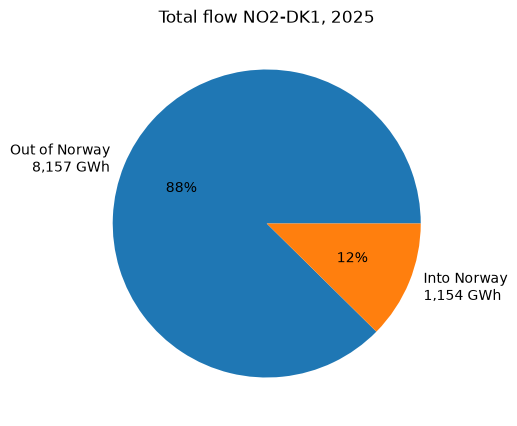

In [20]:
# Direction names are seen from Norway
direction_labels = {"import": "Into Norway", "export": "Out of Norway"}

# Chosen connection and year for both plots
connection = "NO2-DK1"
year = 2025

year_df = daily_df[(daily_df["connection"] == connection) & (daily_df["date"].dt.year == year)]
totals = year_df.groupby("direction")["gwh"].sum()

# Pie of the total amount in and out of Norway over the year
fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(totals, labels=[f"{direction_labels[d]}\n{v:,.0f} GWh" for d, v in totals.items()], autopct="%1.0f%%")
ax.set_title(f"Total flow {connection}, {year}")
plt.show()

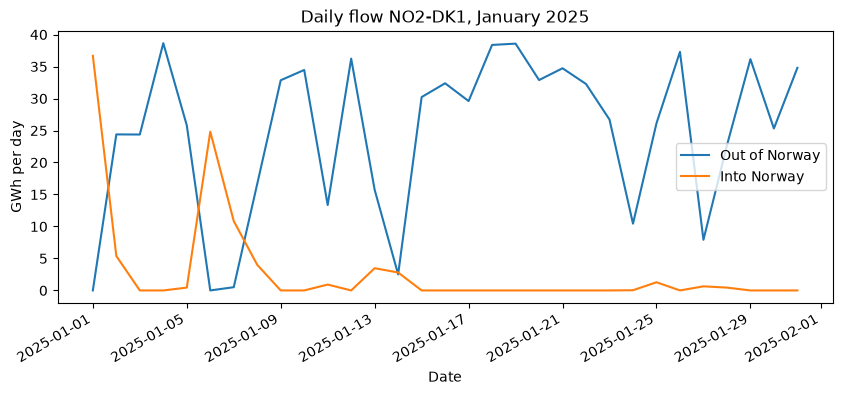

In [21]:
# First month of the year, one line per direction
month_df = year_df[year_df["date"].dt.month == 1]

fig, ax = plt.subplots(figsize=(10, 4))
for direction, direction_df in month_df.groupby("direction"):
    ax.plot(direction_df["date"], direction_df["gwh"], label=direction_labels[direction])
ax.set_xlabel("Date")
ax.set_ylabel("GWh per day")
ax.set_title(f"Daily flow {connection}, January {year}")
ax.legend()
fig.autofmt_xdate()
plt.show()

## MongoDB

The daily data from Spark goes to MongoDB Atlas, where the Streamlit app reads it.

In [22]:
from pymongo import MongoClient

client = MongoClient(secrets["mongo"]["uri"])

# Check that the cluster can be reached (NMBU's VPN can block the connection)
client.admin.command("ping")
print("Connected to MongoDB")

Connected to MongoDB


In [23]:
# Quick test that inserting, updating, reading and deleting works from Python
test = client["ind320"]["test"]
test.insert_one({"name": "test", "value": 1})
test.update_one({"name": "test"}, {"$set": {"value": 2}})
print(test.find_one({"name": "test"}, {"_id": 0}))
test.drop()

{'name': 'test', 'value': 2}


In [24]:
collection = client["ind320"]["flows_daily"]

# Empty the collection first so rerunning the notebook does not give duplicates
collection.delete_many({})
collection.insert_many(daily_df.to_dict("records"))

print(collection.count_documents({}), "documents in flows_daily")
print(collection.find_one({}, {"_id": 0}))

13158 documents in flows_daily
{'connection': 'NO1-SE3', 'direction': 'export', 'date': datetime.datetime(2024, 1, 1, 0, 0), 'gwh': 0.0}


In [25]:
# Close the connections
spark.stop()
cluster.shutdown()
client.close()